
# EnergyPredict AI — Análisis Exploratorio de Datos (EDA)

## 1. Introducción

### Objetivo

El objetivo de este notebook es analizar el comportamiento de la demanda eléctrica en España durante el año 2024, identificando patrones temporales y variables relevantes para desarrollar un modelo de predicción mediante técnicas de Machine Learning.

### Fuente de datos

Los datos proceden de **ENTSO-E (European Network of Transmission System Operators for Electricity)**, a través de su plataforma Transparency Platform.

Se utiliza el conjunto de datos *Actual Total Load*, correspondiente a la demanda eléctrica registrada en España.

### Características del dataset

- **Periodo:** 1 de enero – 31 de diciembre de 2024.
- **Ámbito geográfico:** España.
- **Resolución original:** 15 minutos.
- **Resolución procesada:** 1 hora.
- **Número de observaciones:** 8.784.
- **Variable principal:** demanda eléctrica media horaria (MW).
- **Formato de almacenamiento:** Parquet.

### Preprocesamiento

Antes del análisis, los datos fueron sometidos a un proceso ETL que incluyó:

1. Integración de los 12 archivos mensuales.
2. Filtrado de los registros correspondientes a España.
3. Conversión de fechas y validación de los datos.
4. Identificación e interpolación de un registro ausente.
5. Agregación de los datos a frecuencia horaria.

El resultado es una serie temporal preparada para su análisis y posterior utilización en modelos predictivos.


## 2. Carga y exploración inicial

En esta sección se carga el conjunto de datos procesado en formato Parquet y se realiza una inspección inicial para comprender su estructura y verificar su calidad.

Se analizan las dimensiones del dataset, los tipos de datos, las estadísticas descriptivas de la demanda eléctrica y la presencia de valores nulos.

Esta exploración constituye el punto de partida para identificar posibles anomalías y comprobar que los datos están preparados para el análisis temporal.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargar el dataset procesado
df = pd.read_parquet(
    "../data/processed/demand_spain_2024.parquet"
)

# Inspección inicial
print("Dimensiones:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)

print("\nEstadísticas descriptivas:")
print(df["demand_mw"].describe())

print("\nValores nulos:")
print(df.isnull().sum())

df.head()


Dimensiones: (8784, 3)

Tipos de datos:
datetime_utc              datetime64[us, UTC]
demand_mw                             float64
contains_interpolation                   bool
dtype: object

Estadísticas descriptivas:
count     8784.000000
mean     26444.274306
std       4032.143329
min      17524.000000
25%      23047.750000
50%      26526.000000
75%      29378.500000
max      37937.000000
Name: demand_mw, dtype: float64

Valores nulos:
datetime_utc              0
demand_mw                 0
contains_interpolation    0
dtype: int64


,datetime_utc,demand_mw,contains_interpolation
0,2024-01-01 00:00:00+00:00,21378.0,False
1,2024-01-01 01:00:00+00:00,20286.0,False
2,2024-01-01 02:00:00+00:00,19074.0,False
3,2024-01-01 03:00:00+00:00,18261.0,False
4,2024-01-01 04:00:00+00:00,17899.0,False


## 3. Evolución temporal de la demanda eléctrica

El primer análisis consiste en representar la evolución de la demanda eléctrica española a lo largo de 2024.

**Objetivo:** identificar visualmente fluctuaciones, tendencias, patrones periódicos y posibles valores extremos.

La representación utiliza la demanda media horaria expresada en megavatios (MW). Esta visualización proporciona una perspectiva general del comportamiento de la serie temporal y sirve como punto de partida para los análisis posteriores.

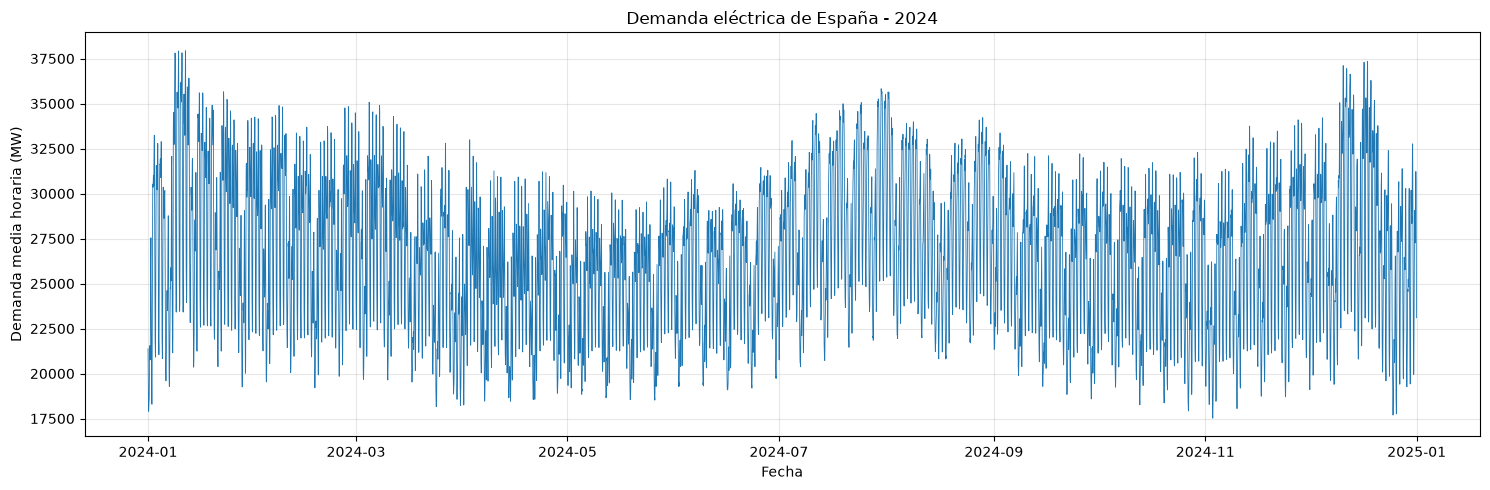

In [4]:

plt.figure(figsize=(15, 5))

plt.plot(
    df["datetime_utc"],
    df["demand_mw"],
    linewidth=0.6,
)

plt.title("Demanda eléctrica de España - 2024")
plt.xlabel("Fecha")
plt.ylabel("Demanda media horaria (MW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Análisis de patrones horarios

La demanda eléctrica presenta variaciones a lo largo del día relacionadas con la actividad económica y los hábitos de consumo.

Para estudiar estas variaciones, se convierten las fechas UTC al horario peninsular español y se calcula la demanda media correspondiente a cada hora del día.

**Objetivo:** identificar las franjas horarias de mayor y menor demanda y evaluar la importancia de la hora como posible variable predictora.

### Interpretación de resultados

El análisis identifica las **21:00 como la hora de mayor demanda media** durante 2024.

Este resultado sugiere la existencia de un patrón diario que podría ser aprovechado por los modelos de Machine Learning mediante la variable `hour`.

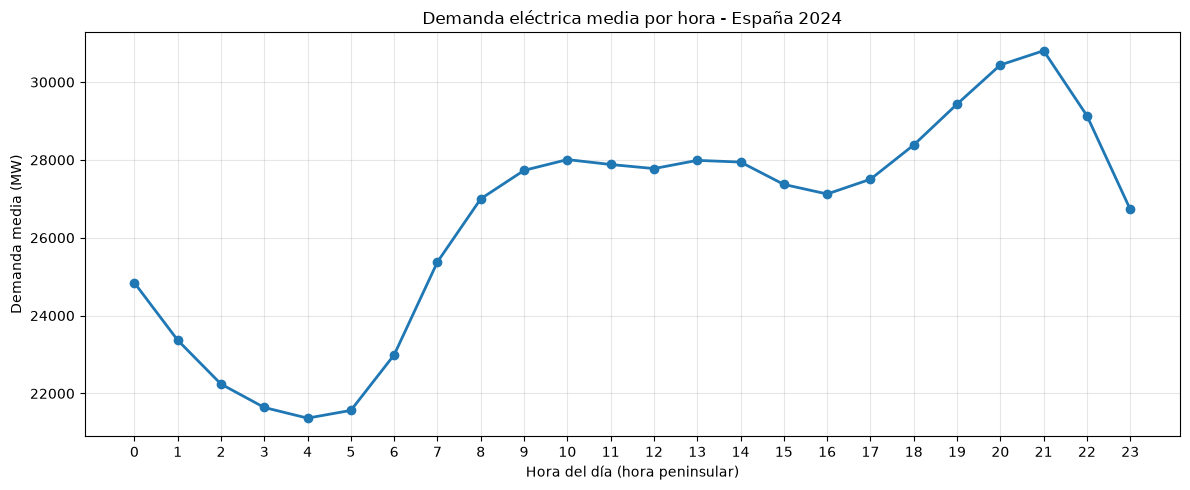

Hora de mayor demanda media: 21:00
Hora de menor demanda media: 04:00


In [5]:
# Convertir las fechas UTC a hora peninsular española
df["datetime_spain"] = df["datetime_utc"].dt.tz_convert(
    "Europe/Madrid"
)

# Extraer la hora del día
df["hour"] = df["datetime_spain"].dt.hour

# Calcular la demanda media de cada hora
hourly_average = df.groupby("hour")["demand_mw"].mean()

# Crear la gráfica
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_average.index,
    hourly_average.values,
    marker="o",
    linewidth=2
)

plt.title("Demanda eléctrica media por hora - España 2024")
plt.xlabel("Hora del día (hora peninsular)")
plt.ylabel("Demanda media (MW)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Mostrar horas de mayor y menor demanda
print(
    "Hora de mayor demanda media:",
    f"{hourly_average.idxmax():02d}:00"
)

print(
    "Hora de menor demanda media:",
    f"{hourly_average.idxmin():02d}:00"
)


## 5. Comparación entre días laborables y fines de semana

El comportamiento de la demanda eléctrica puede variar en función del día de la semana debido a las diferencias en la actividad industrial, comercial y doméstica.

Se clasifican las observaciones en dos categorías:

- **Laborables:** lunes a viernes.
- **Fines de semana:** sábados y domingos.

Posteriormente, se calcula la demanda media por hora para cada categoría.

### Interpretación de resultados

La gráfica muestra una demanda superior durante los días laborables en todas las franjas horarias.

Las diferencias son especialmente pronunciadas durante la mañana, con una demanda aproximada de 29.000 MW en laborables frente a 22.000 MW en fines de semana a las 08:00.

En ambos grupos, la mayor demanda se registra aproximadamente a las 21:00.

Estos resultados sugieren que el día de la semana y la clasificación entre laborables y fines de semana pueden ser variables relevantes para la predicción.

**Limitación:** los días festivos se consideran laborables cuando coinciden de lunes a viernes, por lo que esta clasificación no recoge todas las particularidades del calendario.

/tmp/ipykernel_50781/3048918.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["datetime_spain"].dt.dayofweek


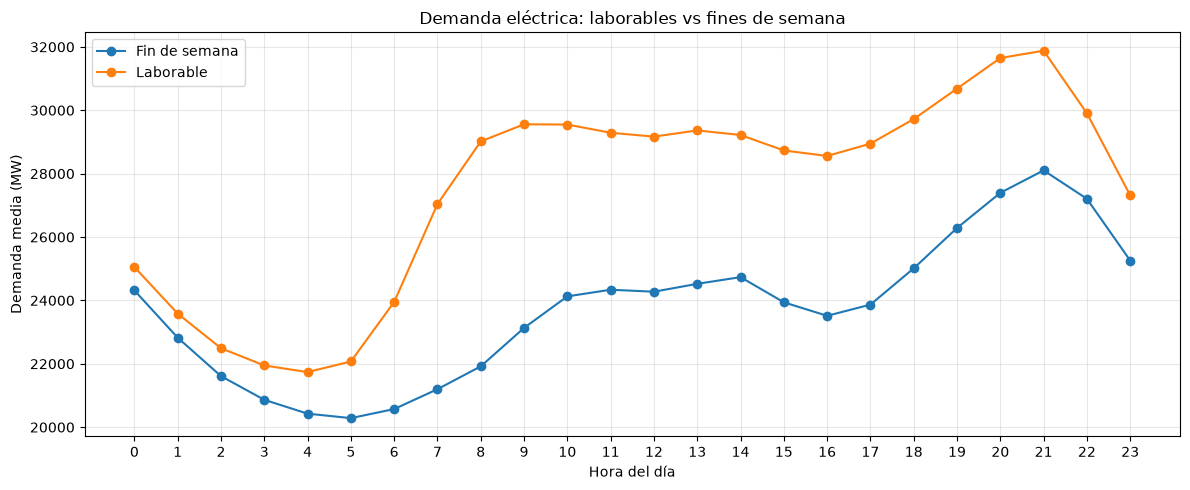


Demanda media por tipo de día:
day_type
Fin de semana    23738.518029
Laborable        27518.314965
Name: demand_mw, dtype: float64


In [6]:
# Extraer el día de la semana
# 0 = lunes, 6 = domingo
df["day_of_week"] = df["datetime_spain"].dt.dayofweek

# Clasificar los registros
df["day_type"] = df["day_of_week"].apply(
    lambda day: "Fin de semana" if day >= 5 else "Laborable"
)

# Calcular la demanda media por tipo de día y hora
comparison = (
    df.groupby(["day_type", "hour"])["demand_mw"]
    .mean()
    .unstack(level=0)
)

# Representar ambas curvas
plt.figure(figsize=(12, 5))

for column in comparison.columns:
    plt.plot(
        comparison.index,
        comparison[column],
        marker="o",
        label=column
    )

plt.title("Demanda eléctrica: laborables vs fines de semana")
plt.xlabel("Hora del día")
plt.ylabel("Demanda media (MW)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nDemanda media por tipo de día:")
print(df.groupby("day_type")["demand_mw"].mean())


## 6. Análisis de estacionalidad mensual

La demanda eléctrica puede experimentar variaciones estacionales relacionadas con factores como la temperatura, las necesidades de climatización, los periodos vacacionales y la actividad económica.

En este apartado se calcula la demanda media horaria de cada mes de 2024.

**Objetivo:** identificar diferencias entre meses y evaluar la existencia de patrones estacionales que puedan ser útiles para el modelo predictivo.

La comparación se realiza mediante valores medios, evitando que los meses de mayor duración presenten automáticamente valores superiores.

### Interpretación de resultados

El análisis mensual muestra diferencias en la demanda eléctrica media a lo largo de 2024, lo que sugiere la existencia de un componente estacional.

**Principales observaciones:**

- **Julio:** presenta la mayor demanda media, aproximadamente 28.600 MW.
- **Enero:** registra también una demanda elevada, cercana a 28.200 MW.
- **Mayo:** presenta la menor demanda media, alrededor de 24.500 MW.
- **Abril y octubre:** muestran niveles de demanda relativamente reducidos respecto a los meses de invierno y verano.

Los resultados sugieren que la demanda eléctrica tiende a aumentar durante los meses más fríos y cálidos del año, mientras que en primavera y otoño se observan valores inferiores.

Este comportamiento podría estar relacionado con las necesidades de calefacción y refrigeración, aunque sería necesario incorporar variables meteorológicas para evaluar dicha relación.

### Implicaciones para Machine Learning

La estacionalidad observada sugiere que el mes del año puede aportar información útil al modelo predictivo.

Por ello, se considera incorporar la variable `month` durante la fase de ingeniería de características (*feature engineering*).

No obstante, al disponer únicamente de datos de 2024, será necesario comprobar si estos patrones se mantienen en otros años antes de considerarlos una estacionalidad recurrente.

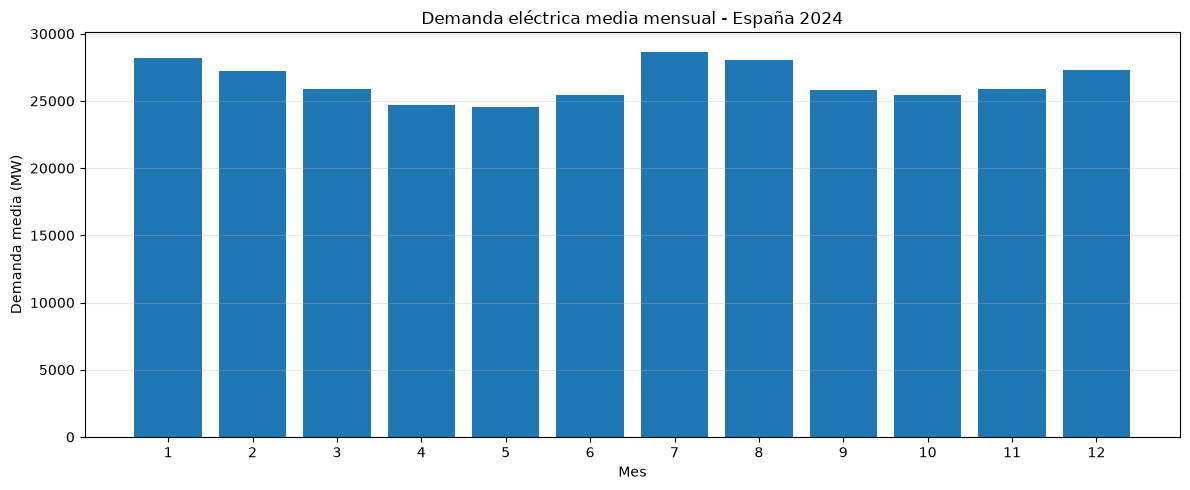

Mes con mayor demanda media: 7
Mes con menor demanda media: 5

Demanda media mensual:
month
1     28208.33
2     27230.85
3     25923.62
4     24733.93
5     24530.51
6     25438.48
7     28672.62
8     28045.98
9     25803.62
10    25444.58
11    25911.58
12    27313.12
Name: demand_mw, dtype: float64


In [7]:
# Extraer el mes
df["month"] = df["datetime_spain"].dt.month

# Demanda media por mes
monthly_average = df.groupby("month")["demand_mw"].mean()

# Crear gráfica
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_average.index,
    monthly_average.values
)

plt.title("Demanda eléctrica media mensual - España 2024")
plt.xlabel("Mes")
plt.ylabel("Demanda media (MW)")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Mes con mayor demanda media:", monthly_average.idxmax())
print("Mes con menor demanda media:", monthly_average.idxmin())
print("\nDemanda media mensual:")
print(monthly_average.round(2))


## 7. Conclusiones preliminares

El análisis exploratorio de la demanda eléctrica española durante 2024 ha permitido identificar varios patrones temporales relevantes.

### Principales hallazgos

1. **Patrones horarios:** la demanda presenta fluctuaciones regulares a lo largo del día, alcanzando su mayor valor medio alrededor de las 21:00.

2. **Diferencias semanales:** los días laborables presentan una demanda media superior a la de los fines de semana, especialmente durante las horas de actividad económica.

3. **Estacionalidad mensual:** se observan diferencias en la demanda media entre los meses del año, con valores elevados en enero y julio y mínimos durante la primavera, especialmente en mayo. Este comportamiento sugiere que la época del año puede influir en la demanda eléctrica.

### Implicaciones para el modelo predictivo

Los resultados preliminares sugieren incorporar las siguientes características:

- `hour`: hora del día.
- `day_of_week`: día de la semana.
- `is_weekend`: indicador de fin de semana.
- `month`: mes del año.

Estas variables podrán complementarse posteriormente con características históricas de la demanda, como retardos (*lags*) y medias móviles.

### Próximos pasos

Profundizar en el análisis de la serie temporal para identificar valores atípicos, dependencias temporales y posibles variables adicionales antes de iniciar el entrenamiento de modelos predictivos.

## 8. Detección y análisis de valores atípicos (Outliers)

### Objetivo

Identificar observaciones de demanda eléctrica que presentan valores significativamente diferentes del comportamiento habitual de la serie temporal.

La detección de valores atípicos es importante porque estos pueden influir en el análisis estadístico y en el rendimiento de los modelos predictivos.

### Metodología

Se utilizará el método del **rango intercuartílico (IQR)**, que permite identificar valores extremos a partir de la distribución de los datos.

Se calculan los siguientes estadísticos:

- **Q1:** primer cuartil (percentil 25).
- **Q3:** tercer cuartil (percentil 75).
- **IQR:** diferencia entre Q3 y Q1.

Se consideran potencialmente atípicos los valores situados fuera de los límites:

- Límite inferior: Q1 − 1,5 × IQR.
- Límite superior: Q3 + 1,5 × IQR.

### Consideraciones

La demanda eléctrica presenta patrones horarios, semanales y estacionales. Por tanto, un valor extremo desde el punto de vista estadístico no implica necesariamente un error.

Los valores detectados se analizarán antes de decidir si deben mantenerse, corregirse o excluirse del conjunto de datos.

In [8]:
# Calcular los cuartiles
Q1 = df["demand_mw"].quantile(0.25)
Q3 = df["demand_mw"].quantile(0.75)

# Calcular el rango intercuartílico
IQR = Q3 - Q1

# Definir los límites
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identificar posibles valores atípicos
df["is_outlier"] = (
    (df["demand_mw"] < lower_bound) |
    (df["demand_mw"] > upper_bound)
)

outliers = df[df["is_outlier"]]

# Mostrar resultados
print(f"Q1: {Q1:.2f} MW")
print(f"Q3: {Q3:.2f} MW")
print(f"IQR: {IQR:.2f} MW")

print(f"\nLímite inferior: {lower_bound:.2f} MW")
print(f"Límite superior: {upper_bound:.2f} MW")

print(f"\nTotal de observaciones: {len(df)}")
print(f"Valores atípicos detectados: {len(outliers)}")

print(
    f"Porcentaje de valores atípicos: "
    f"{len(outliers) / len(df) * 100:.2f}%"
)


Q1: 23047.75 MW
Q3: 29378.50 MW
IQR: 6330.75 MW

Límite inferior: 13551.62 MW
Límite superior: 38874.62 MW

Total de observaciones: 8784
Valores atípicos detectados: 0
Porcentaje de valores atípicos: 0.00%


### 8.1. Visualización de valores atípicos

Para interpretar los resultados se utilizarán dos representaciones:

1. **Diagrama de caja (boxplot):** permite visualizar la distribución de la demanda, la mediana, los cuartiles y los posibles valores extremos.
2. **Serie temporal con valores atípicos destacados:** permite identificar cuándo se producen las observaciones señaladas por el método IQR.

La combinación de ambas visualizaciones facilita distinguir entre valores estadísticamente extremos y posibles anomalías temporales.

/tmp/ipykernel_50781/2805310856.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


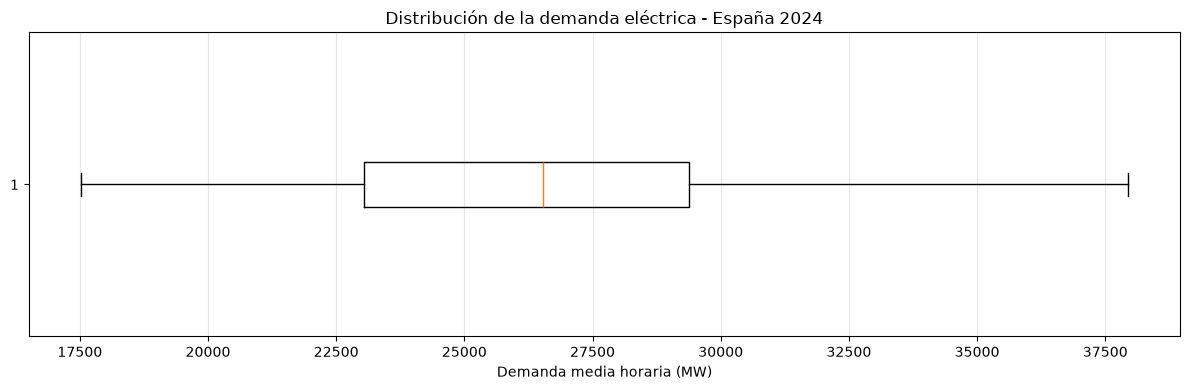

In [9]:
plt.figure(figsize=(12, 4))

plt.boxplot(
    df["demand_mw"],
    vert=False,
    showfliers=True
)

plt.title("Distribución de la demanda eléctrica - España 2024")
plt.xlabel("Demanda media horaria (MW)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


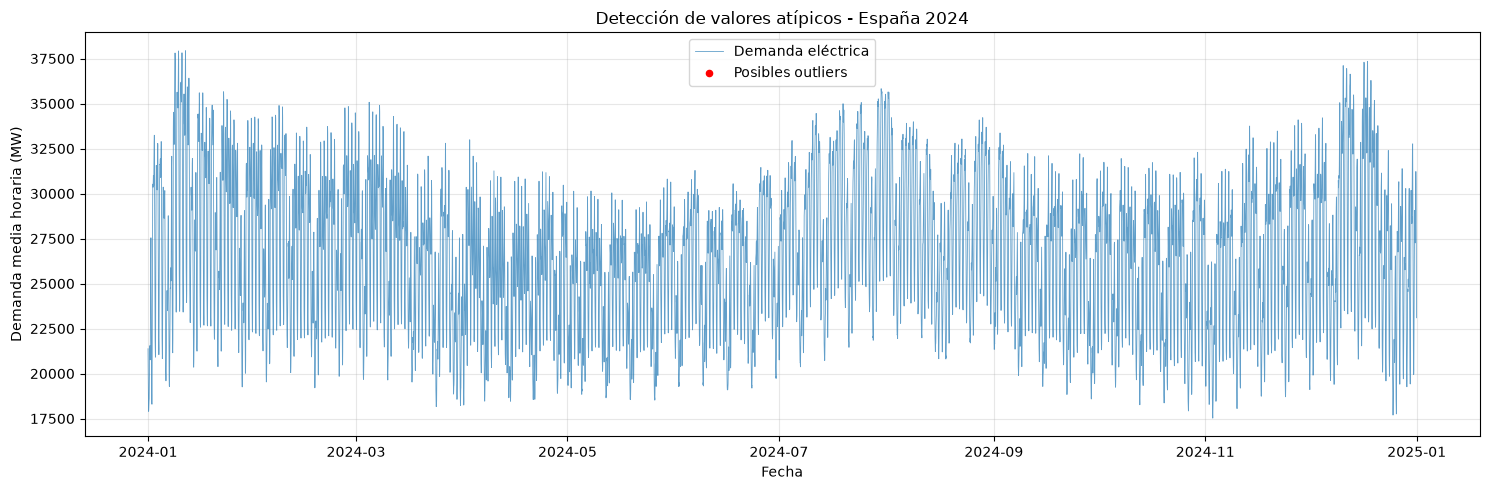

In [10]:
plt.figure(figsize=(15, 5))

# Serie temporal completa
plt.plot(
    df["datetime_utc"],
    df["demand_mw"],
    linewidth=0.6,
    alpha=0.7,
    label="Demanda eléctrica"
)

# Resaltar los valores atípicos
plt.scatter(
    outliers["datetime_utc"],
    outliers["demand_mw"],
    color="red",
    s=20,
    label="Posibles outliers",
    zorder=3
)

plt.title("Detección de valores atípicos - España 2024")
plt.xlabel("Fecha")
plt.ylabel("Demanda media horaria (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:
print("10 observaciones con mayor demanda:")
display(
    df.nlargest(10, "demand_mw")[
        ["datetime_spain", "demand_mw", "is_outlier"]
    ]
)

print("\n10 observaciones con menor demanda:")
display(
    df.nsmallest(10, "demand_mw")[
        ["datetime_spain", "demand_mw", "is_outlier"]
    ]
)


10 observaciones con mayor demanda:


,datetime_spain,demand_mw,is_outlier
259,2024-01-11 20:00:00+01:00,37937.0,False
211,2024-01-09 20:00:00+01:00,37923.0,False
235,2024-01-10 20:00:00+01:00,37820.0,False
187,2024-01-08 20:00:00+01:00,37810.0,False
212,2024-01-09 21:00:00+01:00,37454.0,False
260,2024-01-11 21:00:00+01:00,37451.0,False
210,2024-01-09 19:00:00+01:00,37436.0,False
188,2024-01-08 21:00:00+01:00,37399.0,False
8443,2024-12-17 20:00:00+01:00,37346.0,False
8419,2024-12-16 20:00:00+01:00,37298.0,False



10 observaciones con menor demanda:


,datetime_spain,demand_mw,is_outlier
7372,2024-11-03 05:00:00+01:00,17524.0,False
8620,2024-12-25 05:00:00+01:00,17693.0,False
7371,2024-11-03 04:00:00+01:00,17706.0,False
8643,2024-12-26 04:00:00+01:00,17758.0,False
7373,2024-11-03 06:00:00+01:00,17891.0,False
8621,2024-12-25 06:00:00+01:00,17894.0,False
4,2024-01-01 05:00:00+01:00,17899.0,False
8619,2024-12-25 04:00:00+01:00,17910.0,False
7204,2024-10-27 05:00:00+01:00,17922.0,False
7203,2024-10-27 04:00:00+01:00,17957.0,False


### 8.2. Interpretación de resultados

El análisis mediante el método del rango intercuartílico (IQR) no ha identificado valores atípicos en las 8.784 observaciones horarias correspondientes a 2024.

**Resultados obtenidos:**

- Límite inferior: **13.551,62 MW**.
- Límite superior: **38.874,62 MW**.
- Observaciones atípicas: **0**.
- Porcentaje de valores atípicos: **0,00 %**.

La representación temporal muestra variaciones importantes en la demanda eléctrica, con máximos y mínimos asociados a diferentes momentos del año. Sin embargo, todas las observaciones permanecen dentro del intervalo establecido por el método IQR.

El diagrama de caja confirma que no se detectan valores extremos mediante este criterio.

### Conclusiones

No se considera necesario eliminar ni modificar observaciones por motivos de valores atípicos según el análisis realizado.

No obstante, el método IQR global presenta limitaciones al aplicarse a series temporales con patrones horarios y estacionales. Por ello, la ausencia de valores atípicos estadísticos no garantiza la inexistencia de anomalías locales.

Para el desarrollo del modelo predictivo se conservarán todas las observaciones, incluida la hora que contiene el registro interpolado durante el preprocesamiento.

## 9. Análisis de autocorrelación y dependencias temporales

### Objetivo

Analizar la relación entre la demanda eléctrica registrada en un instante y los valores observados en periodos anteriores.

La autocorrelación permite identificar patrones de dependencia temporal y periodicidades que pueden resultar útiles para desarrollar modelos predictivos.

### Metodología

Se calculará la autocorrelación de la demanda eléctrica para diferentes retardos temporales (*lags*).

Se prestará especial atención a:

- **Lag 1:** demanda registrada una hora antes.
- **Lag 24:** demanda registrada 24 horas antes.
- **Lag 168:** demanda registrada una semana antes.

Además, se representará la autocorrelación para retardos comprendidos entre 1 y 336 horas, equivalentes a dos semanas.

### Aplicación al Machine Learning

Si se identifican correlaciones elevadas en determinados retardos, estos podrán utilizarse como variables predictoras durante la fase de ingeniería de características.

Es importante tener en cuenta que la autocorrelación mide asociación estadística, no causalidad.

Autocorrelaciones de la demanda eléctrica:

Lag   1 horas: 0.9495
Lag   2 horas: 0.8218
Lag   3 horas: 0.6582
Lag  24 horas: 0.7917
Lag  48 horas: 0.5877
Lag  72 horas: 0.5443
Lag 168 horas: 0.8891


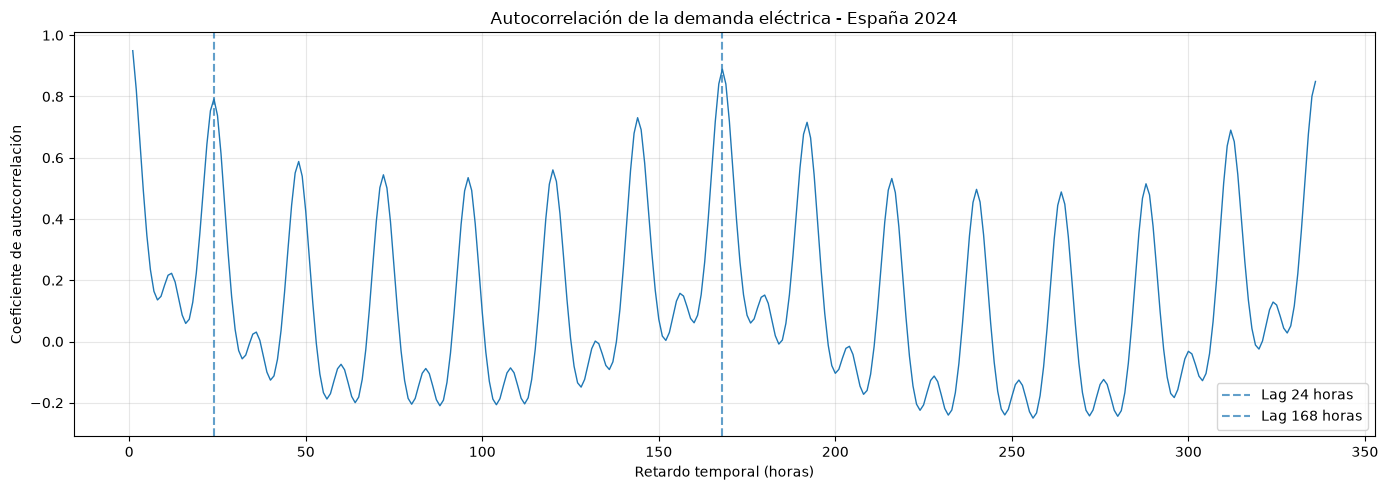

In [12]:
# Calcular autocorrelaciones relevantes
lags = [1, 2, 3, 24, 48, 72, 168]

print("Autocorrelaciones de la demanda eléctrica:\n")

for lag in lags:
    correlation = df["demand_mw"].autocorr(lag=lag)
    print(f"Lag {lag:3d} horas: {correlation:.4f}")

# Calcular autocorrelación hasta 336 horas
max_lag = 336

autocorrelations = [
    df["demand_mw"].autocorr(lag=lag)
    for lag in range(1, max_lag + 1)
]

# Visualización
plt.figure(figsize=(14, 5))

plt.plot(
    range(1, max_lag + 1),
    autocorrelations,
    linewidth=1
)

# Destacar retardos relevantes
for lag in [24, 168]:
    plt.axvline(
        x=lag,
        linestyle="--",
        alpha=0.7,
        label=f"Lag {lag} horas"
    )

plt.title("Autocorrelación de la demanda eléctrica - España 2024")
plt.xlabel("Retardo temporal (horas)")
plt.ylabel("Coeficiente de autocorrelación")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### 9.1. Interpretación de resultados

El análisis de autocorrelación revela una fuerte dependencia temporal en la demanda eléctrica española durante 2024.

**Principales resultados:**

- **Lag 1 (0,9495):** existe una correlación muy elevada entre observaciones consecutivas, lo que indica una importante continuidad en la demanda horaria.
- **Lag 24 (0,7917):** se observa una fuerte dependencia entre la demanda actual y la registrada 24 horas antes, compatible con un patrón diario.
- **Lag 168 (0,8891):** la elevada autocorrelación semanal sugiere que las observaciones correspondientes a la misma hora de semanas consecutivas presentan comportamientos similares.

La representación gráfica muestra picos periódicos de autocorrelación, lo que refuerza la existencia de ciclos temporales en la serie.

### Implicaciones para Machine Learning

Los resultados justifican evaluar variables basadas en observaciones anteriores de la demanda eléctrica:

- `lag_1`: demanda registrada una hora antes.
- `lag_24`: demanda registrada 24 horas antes.
- `lag_168`: demanda registrada una semana antes.

Estas características podrían aportar información predictiva adicional a las variables de calendario identificadas durante el EDA.

No obstante, una autocorrelación elevada no garantiza por sí sola un mejor rendimiento predictivo. Su utilidad deberá comprobarse mediante experimentos con datos no utilizados durante el entrenamiento.

### Conclusión

La demanda eléctrica presenta una estructura temporal marcada, caracterizada por una elevada continuidad entre horas consecutivas y patrones diarios y semanales.

Por tanto, se considera conveniente incorporar características temporales y retardos históricos durante la fase de ingeniería de características.